# Bayesian Media Mix Modelling (PyMC) — Synthetic FMCG Data

This notebook uses **169 weeks of synthetic FMCG data**, with **two competitor brands** and **seven media-spend channels**. All volume-sales measures are in **kg**.


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)

## 1. Load data

In [44]:
# 1. Load the dataset
df=pd.read_csv("MMM_Dataset.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

SOURCE_NCOLS = df.shape[1]

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Rows:", len(df))
print("Source columns:", SOURCE_NCOLS)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Missing values:", int(df.isna().sum().sum()))


Rows: 169
Source columns: 47
Date range: 2023-04-03 to 2026-06-22
Missing values: 0


## 2. Feature engineering

In [45]:
TARGET = "Volume_Sales"  # kg, not number of units

MEDIA_COLS = [
    "Md_OnlineVideo_Spends",
    "Md_Social_Spends",
    "Md_TV_Spends",
    "Md_Digital_Partner_Spends",
    "Md_OOH_Spends",
    "Md_RDM_Spends",
    "Md_Search_Spends",
]
MEDIA_NAMES = [c.replace("Md_", "", 1).replace("_Spends", "") for c in MEDIA_COLS]

comp_cols = [
    "Comp_Brand1_Base_Avg_Price",
    "Comp_Brand2_Base_Avg_Price",
]

REQUIRED_COLS = [
    "Date", TARGET, "Value_Sales",
    "Base_Avg_Price", "Promotion_Avg_Price",
    "weather_average_temp", "weather_rainfall",
    "ACV_Weighted_Distribution_wtd",
    "Promotion_ACV_Weighted_Distribution_wtd",
] + MEDIA_COLS + comp_cols
missing_cols = [col for col in REQUIRED_COLS if col not in df.columns]
if missing_cols:
    raise KeyError(f"Missing expected columns in synthetic dataset: {missing_cols}")

# Promotion discount (price columns denote GBP per kg)
df["Promotion_Discount_Depth"] = np.where(
    df["Base_Avg_Price"] > 0,
    1 - df["Promotion_Avg_Price"] / df["Base_Avg_Price"],
    0,
)
df["Promotion_Discount_Depth"] = df["Promotion_Discount_Depth"].clip(lower=0)

# Average baseline price of the two competitors
df["Competitor_Base_Price_Index"] = df[comp_cols].mean(axis=1)

# Trend and weekly annual seasonality (52-week period)
df["Trend"] = np.arange(len(df), dtype=float)
df["sin52"] = np.sin(2 * np.pi * df["Trend"] / 52)
df["cos52"] = np.cos(2 * np.pi * df["Trend"] / 52)

# From Exploratory nonlinearanalysis heat control (17 C threshold)
df["Heat_Above_17C"] = (df["weather_average_temp"] - 17).clip(lower=0)

BASE_FEATURES = [
    "Trend",
    "sin52",
    "cos52",
    "weather_average_temp",
    "Heat_Above_17C",
    "weather_rainfall",
    "Base_Avg_Price",
    "Promotion_Discount_Depth",
    "ACV_Weighted_Distribution_wtd",
    "Promotion_ACV_Weighted_Distribution_wtd",
    "Competitor_Base_Price_Index",
]

print("Target:", TARGET)
print("Media channels:", MEDIA_NAMES)
print("Base model features:", BASE_FEATURES)

Target: Volume_Sales
Media channels: ['OnlineVideo', 'Social', 'TV', 'Digital_Partner', 'OOH', 'RDM', 'Search']
Base model features: ['Trend', 'sin52', 'cos52', 'weather_average_temp', 'Heat_Above_17C', 'weather_rainfall', 'Base_Avg_Price', 'Promotion_Discount_Depth', 'ACV_Weighted_Distribution_wtd', 'Promotion_ACV_Weighted_Distribution_wtd', 'Competitor_Base_Price_Index']


## 3. Data Training Testing 80/20 split

In [46]:
split = int(len(df) * 0.80)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()

print("Train:", len(train), train["Date"].min().date(), "to", train["Date"].max().date())
print("Test :", len(test), test["Date"].min().date(), "to", test["Date"].max().date())

media_identifiability = pd.DataFrame({
    "Channel": MEDIA_NAMES,
    "Train_active_weeks": [(train[c] > 0).sum() for c in MEDIA_COLS],
    "Test_active_weeks": [(test[c] > 0).sum() for c in MEDIA_COLS],
})

display(media_identifiability)


Train: 135 2023-04-03 to 2025-10-27
Test : 34 2025-11-03 to 2026-06-22


,Channel,Train_active_weeks,Test_active_weeks
0,OnlineVideo,20,3
1,Social,23,8
2,TV,5,0
3,Digital_Partner,9,6
4,OOH,6,1
5,RDM,38,11
6,Search,11,1


## 4. Base Ridge model

In [47]:

X_base = df[BASE_FEATURES].astype(float)
y = df[TARGET].astype(float)

X_train = X_base.iloc[:split]
X_test = X_base.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

base_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", Ridge()),
])

base_search = GridSearchCV(
    base_pipe,
    {"ridge__alpha": np.logspace(-3, 4, 80)},
    scoring="neg_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=5),
)

base_search.fit(X_train, y_train)

base_train_pred = base_search.predict(X_train)
base_test_pred = base_search.predict(X_test)

def metrics(actual, pred):
    actual = np.asarray(actual)
    pred = np.asarray(pred)
    return {
        "R2": r2_score(actual, pred),
        "RMSE": mean_squared_error(actual, pred) ** 0.5,
        "MAE": mean_absolute_error(actual, pred),
        "MAPE": np.mean(np.abs((actual - pred) / actual)) * 100,
    }

base_metrics = metrics(y_test, base_test_pred)

print("BASE RIDGE")
for k, v in base_metrics.items():
    print(f"{k:10s}: {v:,.3f}")


BASE RIDGE
R2        : 0.897
RMSE      : 197,992.766
MAE       : 143,775.127
MAPE      : 4.649


## 5. Media transformations

In [48]:

def geometric_adstock(x, decay):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    for t in range(len(x)):
        out[t] = x[t] + (decay * out[t-1] if t > 0 else 0)
    return out

def hill_saturation(x, slope=1.5, half_saturation=1.0):
    x = np.maximum(np.asarray(x, dtype=float), 0)
    num = x ** slope
    den = num + half_saturation ** slope
    return np.divide(num, den, out=np.zeros_like(x), where=den != 0)

DECAY_GRID = [0.0, 0.2, 0.4, 0.6, 0.8]


In [49]:
def cv_rmse(X, y):
    errors = []

    for tr, va in TimeSeriesSplit(n_splits=5).split(X):
        model = Pipeline([
            ("scale", StandardScaler()),
            ("ridge", Ridge(alpha=20)),
        ])

        model.fit(X.iloc[tr], y.iloc[tr])
        pred = model.predict(X.iloc[va])

        errors.extend((y.iloc[va].values - pred) ** 2)

    return np.sqrt(np.mean(errors))


MEDIA_TRANSFORMED = pd.DataFrame(index=df.index)
adstock_results = []

for channel in MEDIA_COLS:

    positive_train = train.loc[train[channel] > 0, channel]
    spend_scale = positive_train.mean() if len(positive_train) else 1.0

    scaled = df[channel].fillna(0).values / spend_scale

    best_decay = 0.3
    best_rmse = np.nan

    if len(positive_train) >= 3:

        candidates = []

        for decay in DECAY_GRID:
            transformed = hill_saturation(
                geometric_adstock(scaled, decay),
                slope=1.5,
                half_saturation=1.0,
            )

            X_tmp = X_base.copy()
            X_tmp["Media_Test"] = transformed

            rmse = cv_rmse(
                X_tmp.iloc[:split],
                y.iloc[:split],
            )

            candidates.append((rmse, decay))

        best_rmse, best_decay = min(candidates)

    transformed = hill_saturation(
        geometric_adstock(scaled, best_decay),
        slope=1.5,
        half_saturation=1.0,
    )

    MEDIA_TRANSFORMED[channel + "_AdstockHill"] = transformed

    adstock_results.append({
        "Channel": channel.replace("Md_", "", 1).replace("_Spends", ""),
        "Training_Active_Weeks": len(positive_train),
        "Selected_Decay": best_decay,
        "CV_RMSE": best_rmse,
    })

adstock_results = pd.DataFrame(adstock_results)
display(adstock_results)

,Channel,Training_Active_Weeks,Selected_Decay,CV_RMSE
0,OnlineVideo,20,0.6,380212.653565
1,Social,23,0.0,392750.178833
2,TV,5,0.4,390142.363195
3,Digital_Partner,9,0.8,334352.209696
4,OOH,6,0.0,395804.304180
5,RDM,38,0.0,396371.070182
6,Search,11,0.0,395546.438049


## 6. PyMC Bayesian MMM

In [50]:

import pymc as pm
import arviz as az

print("PyMC:", pm.__version__)
print("ArviZ:", az.__version__)


PyMC: 5.28.5
ArviZ: 0.22.0


In [51]:
M_raw = MEDIA_TRANSFORMED.values.astype(float)

# Controls: train-only scaling
control_scaler = StandardScaler()

X_control_train_z = control_scaler.fit_transform(X_train)
X_control_test_z = control_scaler.transform(X_test)


media_scale = np.where(
    M_raw[:split].std(axis=0) > 0,
    M_raw[:split].std(axis=0),
    1.0,
)

M_train_bayes = M_raw[:split] / media_scale
M_test_bayes = M_raw[split:] / media_scale

# Target: train-only scaling
Y_MEAN = y_train.mean()
Y_SD = y_train.std()

y_train_z = (y_train.values - Y_MEAN) / Y_SD

coords = {
    "date_train": train["Date"].values,
    "control": BASE_FEATURES,
    "media": MEDIA_NAMES,
}


In [52]:

with pm.Model(coords=coords) as bayesian_mmm:

    Xc = pm.Data(
        "X_controls",
        X_control_train_z,
        dims=("date_train", "control"),
    )

    Xm = pm.Data(
        "X_media",
        M_train_bayes,
        dims=("date_train", "media"),
    )

    intercept = pm.Normal(
        "intercept",
        mu=0,
        sigma=0.5,
    )

    control_beta = pm.Normal(
        "control_beta",
        mu=0,
        sigma=0.35,
        dims="control",
    )

    media_beta_scale = pm.HalfNormal(
        "media_beta_scale",
        sigma=0.30,
    )

    media_beta = pm.HalfNormal(
        "media_beta",
        sigma=media_beta_scale,
        dims="media",
    )

    control_part = (Xc * control_beta).sum(axis=1)
    media_part = (Xm * media_beta).sum(axis=1)

    mu = pm.Deterministic(
        "mu",
        intercept + control_part + media_part,
        dims="date_train",
    )

    sigma = pm.HalfNormal(
        "sigma",
        sigma=0.5,
    )

    nu_minus_two = pm.Exponential(
        "nu_minus_two",
        lam=1/20,
    )

    nu = pm.Deterministic(
        "nu",
        nu_minus_two + 2,
    )

    sales = pm.StudentT(
        "sales",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=y_train_z,
        dims="date_train",
    )


In [53]:

with bayesian_mmm:

    trace = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        return_inferencedata=True,
    )


Output()

## 7. Bayesian convergence diagnostics

In [54]:

diag = az.summary(
    trace,
    var_names=[
        "media_beta",
        "control_beta",
        "sigma",
        "nu",
    ],
    hdi_prob=0.95,
    round_to=3,
)

display(diag)

divergences = int(trace.sample_stats["diverging"].sum())

print("Divergences:", divergences)
print("Max R-hat:", diag["r_hat"].max())
print("Min bulk ESS:", diag["ess_bulk"].min())


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
media_beta[OnlineVideo],0.116,0.021,0.075,0.157,0.000,0.000,5029.792,4051.917,1.000
media_beta[Social],0.082,0.019,0.044,0.118,0.000,0.000,5095.851,3567.015,1.000
media_beta[TV],0.052,0.019,0.012,0.088,0.000,0.000,2648.773,1851.327,1.001
media_beta[Digital_Partner],0.074,0.023,0.027,0.119,0.000,0.000,3079.639,2082.751,1.002
media_beta[OOH],0.050,0.018,0.015,0.084,0.000,0.000,4906.473,2381.477,1.001
media_beta[RDM],0.076,0.019,0.039,0.112,0.000,0.000,5389.859,3109.171,1.001
media_beta[Search],0.041,0.018,0.007,0.075,0.000,0.000,3740.948,1811.633,1.002
control_beta[Trend],0.123,0.088,-0.050,0.289,0.001,0.001,3906.204,3944.663,1.001
control_beta[sin52],0.501,0.067,0.368,0.633,0.001,0.001,2572.999,3587.519,1.001
control_beta[cos52],0.375,0.041,0.294,0.452,0.001,0.000,2937.699,3807.468,1.001


Divergences: 0
Max R-hat: 1.002
Min bulk ESS: 2470.433


## 8. Bayesian holdout prediction

In [55]:

posterior = trace.posterior.stack(sample=("chain", "draw"))

intercept_draws = posterior["intercept"].values

control_beta_draws = (
    posterior["control_beta"]
    .transpose("sample", "control")
    .values
)

media_beta_draws = (
    posterior["media_beta"]
    .transpose("sample", "media")
    .values
)

# posterior sample x test week
bayes_test_pred_z = (
    intercept_draws[:, None]
    + control_beta_draws @ X_control_test_z.T
    + media_beta_draws @ M_test_bayes.T
)

bayes_test_pred = Y_MEAN + Y_SD * bayes_test_pred_z

bayes_test_mean = bayes_test_pred.mean(axis=0)
bayes_test_low = np.quantile(bayes_test_pred, 0.025, axis=0)
bayes_test_high = np.quantile(bayes_test_pred, 0.975, axis=0)

bayes_metrics = metrics(y_test, bayes_test_mean)

print("PYMC BAYESIAN MMM")
for k, v in bayes_metrics.items():
    print(f"{k:10s}: {v:,.3f}")


PYMC BAYESIAN MMM
R2        : 0.951
RMSE      : 136,396.767
MAE       : 108,397.546
MAPE      : 3.369


# 9. Predictive validation

In [56]:
model_comparison = pd.DataFrame([
    {"Model": "Base Ridge - no media", **base_metrics},
    {"Model": "PyMC Bayesian MMM", **bayes_metrics},
])

display(
    model_comparison.style.format({
        "R2": "{:.3f}",
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.2f}%",
    })
)


,Model,R2,RMSE,MAE,MAPE
0,Base Ridge - no media,0.897,"197,993","143,775",4.65%
1,PyMC Bayesian MMM,0.951,"136,397","108,398",3.37%


## 10 Bayesian MMM — holdout prediction graph


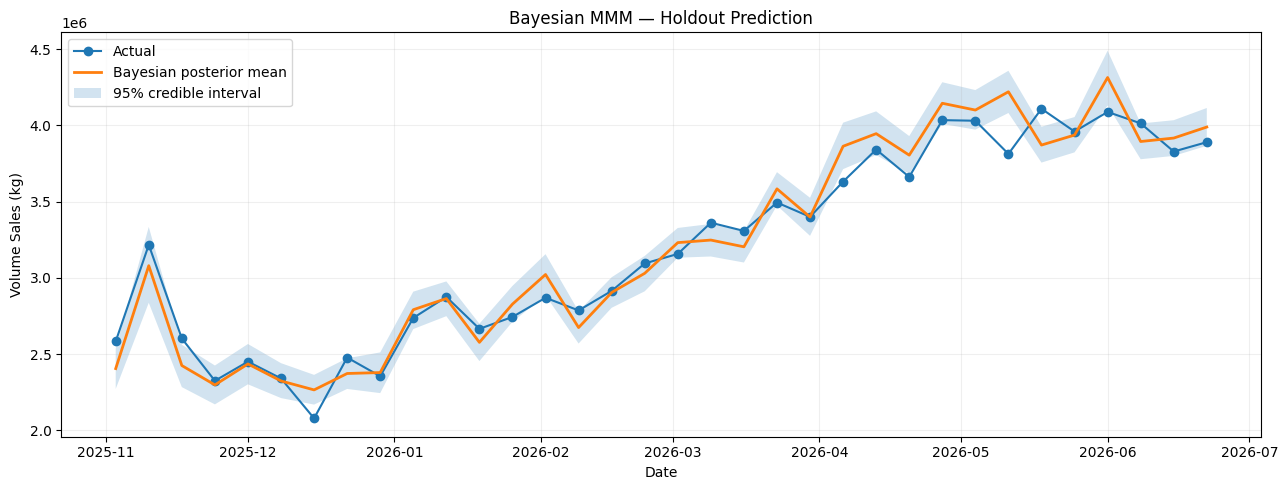

In [57]:
plt.figure(figsize=(13, 5))

plt.plot(
    test["Date"],
    y_test.values,
    marker="o",
    label="Actual",
)

plt.plot(
    test["Date"],
    bayes_test_mean,
    linewidth=2,
    label="Bayesian posterior mean",
)

plt.fill_between(
    test["Date"],
    bayes_test_low,
    bayes_test_high,
    alpha=0.20,
    label="95% credible interval",
)

plt.title("Bayesian MMM — Holdout Prediction")
plt.xlabel("Date")
plt.ylabel("Volume Sales (kg)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


## 11. Bayesian MMM — full-history attribution and business outputs


In [58]:
# BAYESIAN FULL-HISTORY PREPARATION

control_scaler_full = StandardScaler()
X_control_full_z = control_scaler_full.fit_transform(X_base)

full_media_scale = np.where(
    M_raw.std(axis=0) > 0,
    M_raw.std(axis=0),
    1.0,
)

M_full_bayes = M_raw / full_media_scale

Y_FULL_MEAN = y.mean()
Y_FULL_SD = y.std()

y_full_z = (
    y.values - Y_FULL_MEAN
) / Y_FULL_SD

coords_full = {
    "date": df["Date"].values,
    "control": BASE_FEATURES,
    "media": MEDIA_NAMES,
}


In [59]:
# BAYESIAN FULL-HISTORY MODEL

with pm.Model(coords=coords_full) as bayesian_mmm_full:

    Xc = pm.Data(
        "X_controls",
        X_control_full_z,
        dims=("date", "control"),
    )

    Xm = pm.Data(
        "X_media",
        M_full_bayes,
        dims=("date", "media"),
    )

    intercept = pm.Normal(
        "intercept",
        mu=0,
        sigma=0.5,
    )

    control_beta = pm.Normal(
        "control_beta",
        mu=0,
        sigma=0.35,
        dims="control",
    )

    media_beta_scale = pm.HalfNormal(
        "media_beta_scale",
        sigma=0.30,
    )

    # Positive media-effect prior
    media_beta = pm.HalfNormal(
        "media_beta",
        sigma=media_beta_scale,
        dims="media",
    )

    media_contribution_z = pm.Deterministic(
        "media_contribution_z",
        Xm * media_beta,
        dims=("date", "media"),
    )

    mu = pm.Deterministic(
        "mu",
        intercept
        + (Xc * control_beta).sum(axis=1)
        + media_contribution_z.sum(axis=1),
        dims="date",
    )

    sigma = pm.HalfNormal(
        "sigma",
        sigma=0.5,
    )

    nu_minus_two = pm.Exponential(
        "nu_minus_two",
        lam=1/20,
    )

    nu = pm.Deterministic(
        "nu",
        nu_minus_two + 2,
    )

    sales = pm.StudentT(
        "sales",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=y_full_z,
        dims="date",
    )


with bayesian_mmm_full:

    trace_full = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        return_inferencedata=True,
    )


Output()

In [60]:
# BAYESIAN FULL-HISTORY CONTRIBUTION

media_post = (
    trace_full.posterior["media_contribution_z"]
    .stack(sample=("chain", "draw"))
    .transpose("sample", "date", "media")
    .values
)

# sample x date x media, converted back to kg
media_contribution_kg = (
    media_post * Y_FULL_SD
)

# sample x media
bayes_channel_total_draws = (
    media_contribution_kg.sum(axis=1)
)

bayes_mean = (
    bayes_channel_total_draws.mean(axis=0)
)

bayes_low = np.quantile(
    bayes_channel_total_draws,
    0.025,
    axis=0,
)

bayes_high = np.quantile(
    bayes_channel_total_draws,
    0.975,
    axis=0,
)

bayesian_attribution = pd.DataFrame({
    "Channel": MEDIA_NAMES,
    "Bayesian_Incremental_kg": bayes_mean,
    "Bayesian_Lower95": bayes_low,
    "Bayesian_Upper95": bayes_high,
})

bayesian_attribution["Bayesian_Share_pct"] = (
    bayesian_attribution["Bayesian_Incremental_kg"]
    / bayesian_attribution["Bayesian_Incremental_kg"].sum()
    * 100
)

display(
    bayesian_attribution
    .sort_values("Bayesian_Incremental_kg", ascending=False)
    .style.format({
        "Bayesian_Incremental_kg": "{:,.0f}",
        "Bayesian_Lower95": "{:,.0f}",
        "Bayesian_Upper95": "{:,.0f}",
        "Bayesian_Share_pct": "{:.1f}%",
    })
)


,Channel,Bayesian_Incremental_kg,Bayesian_Lower95,Bayesian_Upper95,Bayesian_Share_pct
3,Digital_Partner,"11,419,392","7,188,100","15,496,414",34.8%
0,OnlineVideo,"8,397,690","5,471,991","11,317,800",25.6%
5,RDM,"4,695,813","2,625,548","6,789,660",14.3%
1,Social,"4,338,171","2,836,242","5,881,880",13.2%
6,Search,"1,479,363","659,511","2,302,060",4.5%
2,TV,"1,376,893","473,524","2,289,989",4.2%
4,OOH,"1,089,625","366,919","1,795,647",3.3%


### 11.1 Bayesian — media contribution by channel


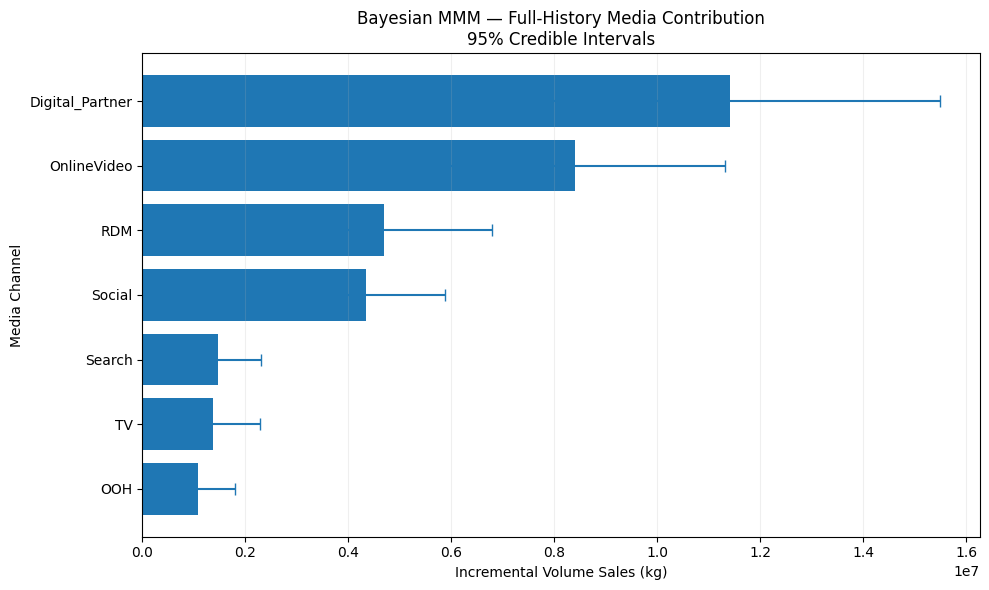

In [61]:
bayes_plot = (
    bayesian_attribution
    .sort_values("Bayesian_Incremental_kg", ascending=True)
    .reset_index(drop=True)
)

lower_error = (
    bayes_plot["Bayesian_Incremental_kg"]
    - bayes_plot["Bayesian_Lower95"]
)

upper_error = (
    bayes_plot["Bayesian_Upper95"]
    - bayes_plot["Bayesian_Incremental_kg"]
)

plt.figure(figsize=(10, 6))

plt.barh(
    bayes_plot["Channel"],
    bayes_plot["Bayesian_Incremental_kg"],

)
plt.errorbar(
    bayes_plot["Bayesian_Incremental_kg"],
    bayes_plot["Channel"],
    xerr=[lower_error, upper_error],
    fmt="none",
    capsize=4,
)

plt.xlabel("Incremental Volume Sales (kg)")
plt.ylabel("Media Channel")
plt.title(
    "Bayesian MMM — Full-History Media Contribution\n"
    "95% Credible Intervals"
)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### 11.2 Bayesian — incremental media sales over time


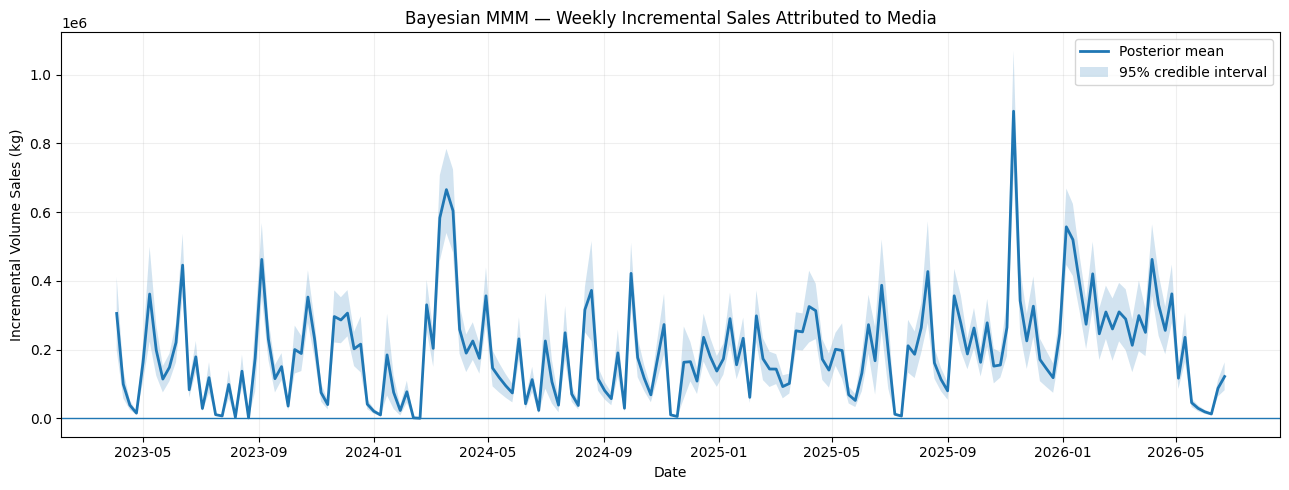

In [62]:
# sample x date
bayes_weekly_total_draws = (
    media_contribution_kg.sum(axis=2)
)

bayes_weekly_total_mean = (
    bayes_weekly_total_draws.mean(axis=0)
)

bayes_weekly_total_low = np.quantile(
    bayes_weekly_total_draws,
    0.025,
    axis=0,
)

bayes_weekly_total_high = np.quantile(
    bayes_weekly_total_draws,
    0.975,
    axis=0,
)

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    bayes_weekly_total_mean,
    linewidth=2,
    label="Posterior mean",
)

plt.fill_between(
    df["Date"],
    bayes_weekly_total_low,
    bayes_weekly_total_high,
    alpha=0.20,
    label="95% credible interval",
)

plt.axhline(0, linewidth=1)

plt.title("Bayesian MMM — Weekly Incremental Sales Attributed to Media")
plt.xlabel("Date")
plt.ylabel("Incremental Volume Sales (kg)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


### 11.3 Bayesian — incremental-sales response curves


In [63]:
# RESPONSE-CURVE INPUTS

response_curve_inputs = {}

for j, channel in enumerate(MEDIA_COLS):

    channel_name = MEDIA_NAMES[j]

    positive_train = train.loc[train[channel] > 0, channel]
    spend_scale = positive_train.mean() if len(positive_train) else 1.0

    historical_positive = df.loc[df[channel] > 0, channel]

    if len(historical_positive) == 0:
        continue

    decay = float(
        adstock_results.loc[
            adstock_results["Channel"] == channel_name,
            "Selected_Decay"
        ].iloc[0]
    )

    spend_grid = np.linspace(
        0,
        historical_positive.max() * 1.50,
        120,
    )

    scaled_spend = spend_grid / spend_scale

    if decay < 0.999:
        steady_state_adstock = scaled_spend / (1.0 - decay)
    else:
        steady_state_adstock = scaled_spend

    transformed_grid = hill_saturation(
        steady_state_adstock,
        slope=1.5,
        half_saturation=1.0,
    )

    response_curve_inputs[channel_name] = {
        "channel_col": channel,
        "spend_grid": spend_grid,
        "transformed_grid": transformed_grid,
        "decay": decay,
        # Use the average only across weeks when this channel was active.
        # Including zero-spend weeks would understate typical campaign spend.
        "historical_active_week_average_spend": float(historical_positive.mean()),
    }

print("Prepared response curves for:", list(response_curve_inputs))


Prepared response curves for: ['OnlineVideo', 'Social', 'TV', 'Digital_Partner', 'OOH', 'RDM', 'Search']


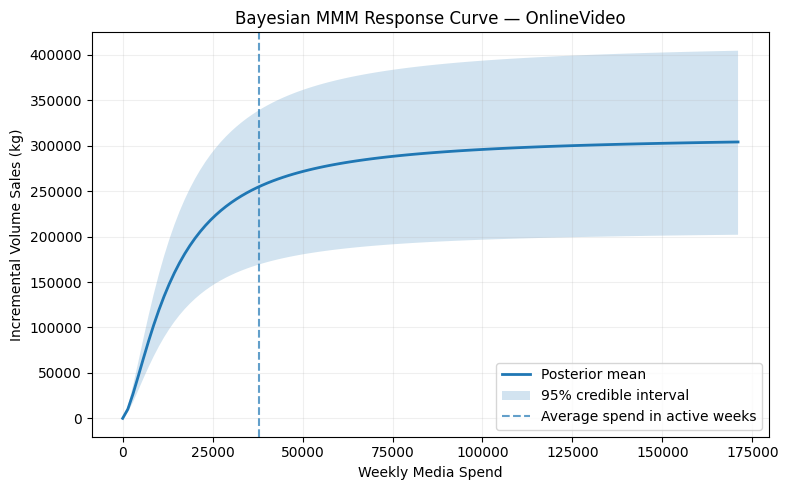

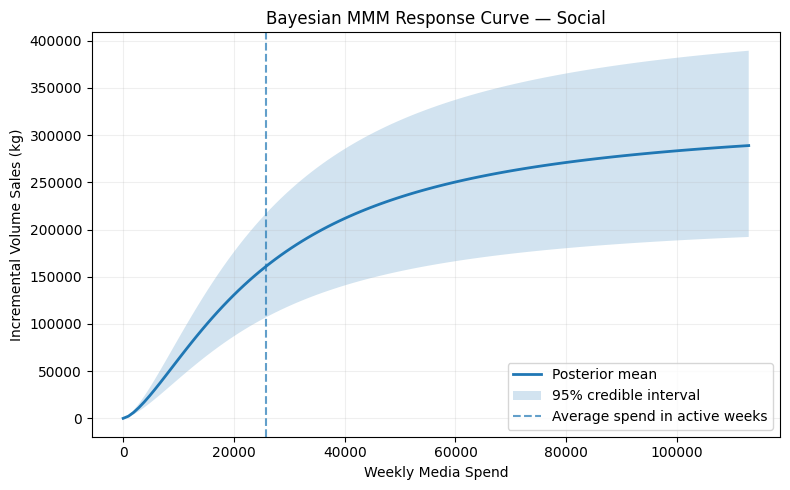

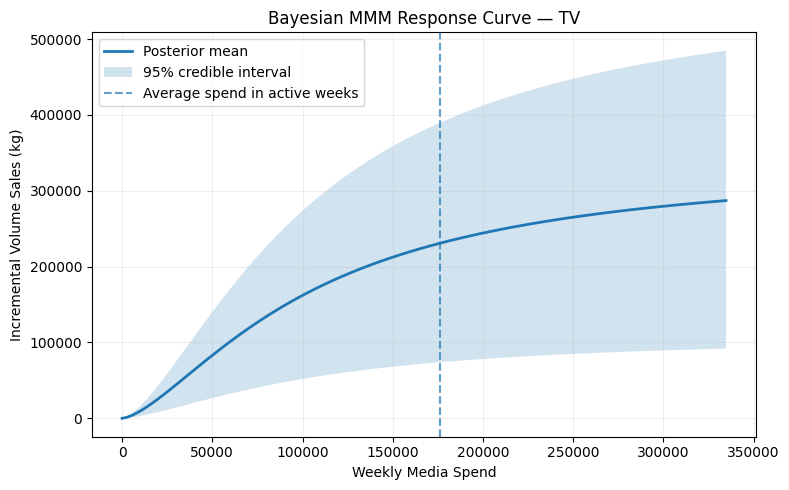

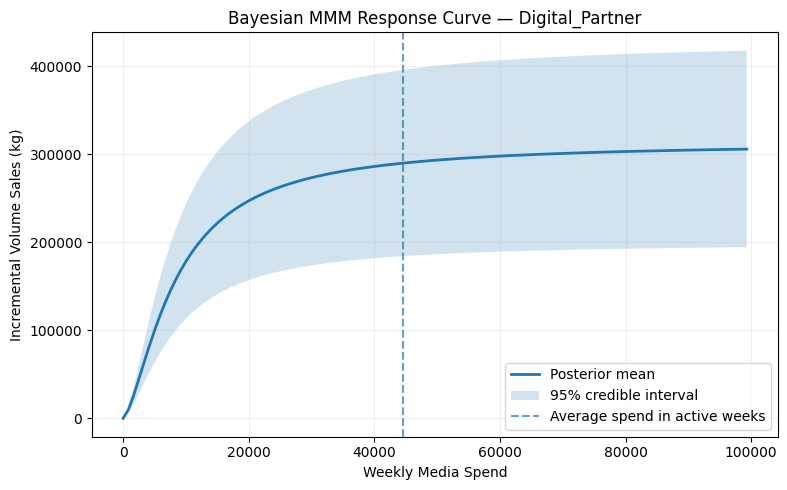

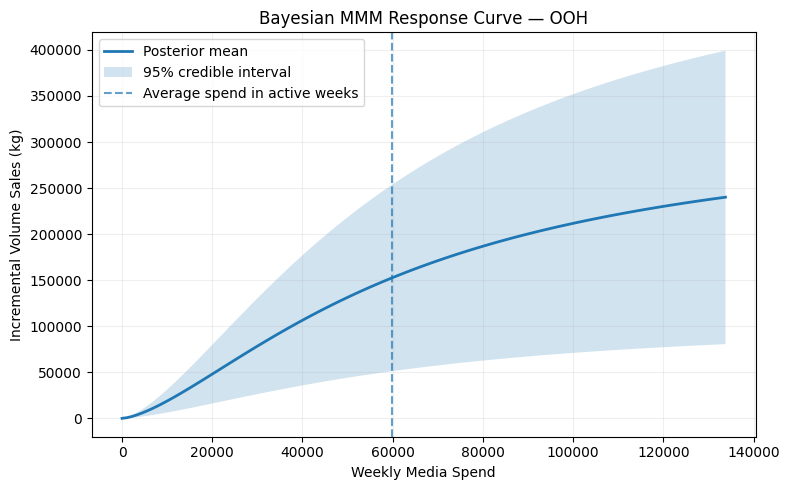

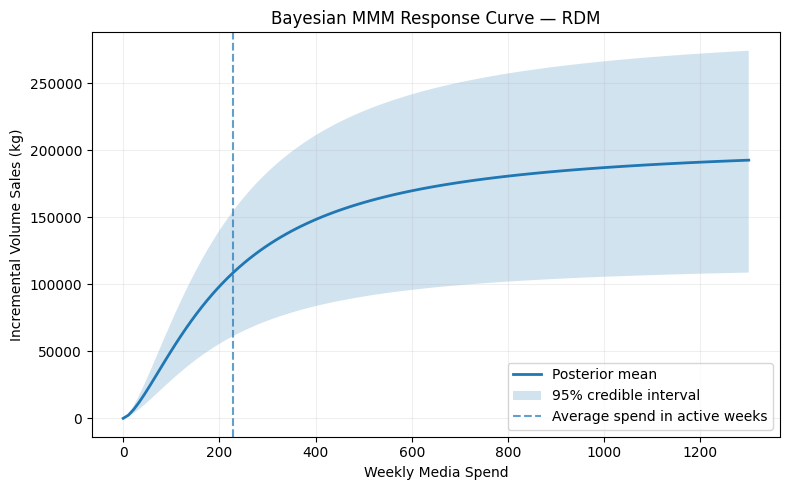

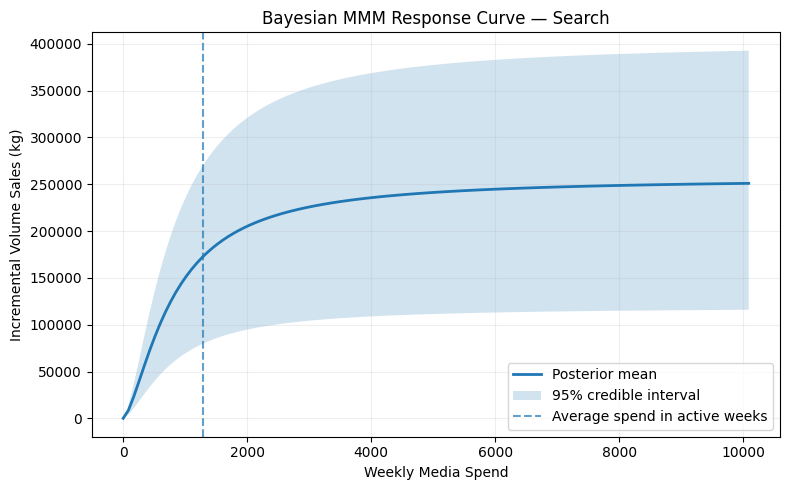

In [38]:
# BAYESIAN RESPONSE CURVES — ONE GRAPH PER CHANNEL


posterior_full = (
    trace_full.posterior
    .stack(sample=("chain", "draw"))
)

media_beta_full_draws = (
    posterior_full["media_beta"]
    .transpose("sample", "media")
    .values
)

bayesian_response_tables = []

for j, channel_name in enumerate(MEDIA_NAMES):

    if channel_name not in response_curve_inputs:
        continue

    info = response_curve_inputs[channel_name]

    spend_grid = info["spend_grid"]
    transformed_grid = info["transformed_grid"]

    transformed_for_bayes = (
        transformed_grid
        / full_media_scale[j]
    )

    # sample x spend level, converted from standardized y to kg
    response_draws_kg = (
        media_beta_full_draws[:, j, None]
        * transformed_for_bayes[None, :]
        * Y_FULL_SD
    )

    response_mean = (
        response_draws_kg.mean(axis=0)
    )

    response_low = np.quantile(
        response_draws_kg,
        0.025,
        axis=0,
    )

    response_high = np.quantile(
        response_draws_kg,
        0.975,
        axis=0,
    )

    response_df = pd.DataFrame({
        "Channel": channel_name,
        "Weekly_Spend": spend_grid,
        "Bayesian_Incremental_kg": response_mean,
        "Bayesian_Lower95": response_low,
        "Bayesian_Upper95": response_high,
    })

    bayesian_response_tables.append(response_df)

    plt.figure(figsize=(8, 5))

    plt.plot(
        spend_grid,
        response_mean,
        linewidth=2,
        label="Posterior mean",
    )

    plt.fill_between(
        spend_grid,
        response_low,
        response_high,
        alpha=0.20,
        label="95% credible interval",
    )

    plt.axvline(
        info["historical_active_week_average_spend"],
        linestyle="--",
        alpha=0.7,
        label="Average spend in active weeks",
    )

    plt.xlabel("Weekly Media Spend")
    plt.ylabel("Incremental Volume Sales (kg)")
    plt.title(
        f"Bayesian MMM Response Curve — {channel_name}"
    )
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

bayesian_response_curves = pd.concat(
    bayesian_response_tables,
    ignore_index=True,
) if bayesian_response_tables else pd.DataFrame()


### 11.4 Bayesian — ROAS


In [39]:
# BAYESIAN ROAS

spend_by_channel = (
    df[MEDIA_COLS]
    .sum()
    .values
    .astype(float)
)

spend_safe = np.where(
    spend_by_channel > 0,
    spend_by_channel,
    np.nan,
)


average_revenue_per_kg = (
    df["Value_Sales"].sum()
    / df["Volume_Sales"].sum()
)

bayes_incremental_revenue_draws = (
    bayes_channel_total_draws
    * average_revenue_per_kg
)

bayes_roas_draws = (
    bayes_incremental_revenue_draws
    / spend_safe[None, :]
)

bayesian_roas_df = pd.DataFrame({
    "Channel": MEDIA_NAMES,
    "Total_Spend": spend_by_channel,
    "Bayesian_Incremental_Revenue": np.nanmean(
        bayes_incremental_revenue_draws,
        axis=0,
    ),
    "Bayesian_ROAS": np.nanmean(
        bayes_roas_draws,
        axis=0,
    ),
    "Bayesian_ROAS_Lower95": np.nanquantile(
        bayes_roas_draws,
        0.025,
        axis=0,
    ),
    "Bayesian_ROAS_Upper95": np.nanquantile(
        bayes_roas_draws,
        0.975,
        axis=0,
    ),
})

display(
    bayesian_roas_df
    .sort_values("Bayesian_ROAS", ascending=False)
    .style.format({
        "Total_Spend": "£{:,.0f}",
        "Bayesian_Incremental_Revenue": "£{:,.0f}",
        "Bayesian_ROAS": "{:.2f}x",
        "Bayesian_ROAS_Lower95": "{:.2f}x",
        "Bayesian_ROAS_Upper95": "{:.2f}x",
    })
)


,Channel,Total_Spend,Bayesian_Incremental_Revenue,Bayesian_ROAS,Bayesian_ROAS_Lower95,Bayesian_ROAS_Upper95
5,RDM,"£11,193","£4,283,618",382.71x,216.06x,544.94x
6,Search,"£15,466","£1,312,277",84.85x,39.20x,132.75x
3,Digital_Partner,"£669,543","£10,271,617",15.34x,9.75x,20.95x
0,OnlineVideo,"£872,879","£7,913,010",9.07x,6.02x,12.06x
1,Social,"£799,684","£3,986,885",4.99x,3.32x,6.72x
4,OOH,"£418,998","£938,057",2.24x,0.75x,3.72x
2,TV,"£879,766","£1,192,714",1.36x,0.43x,2.29x


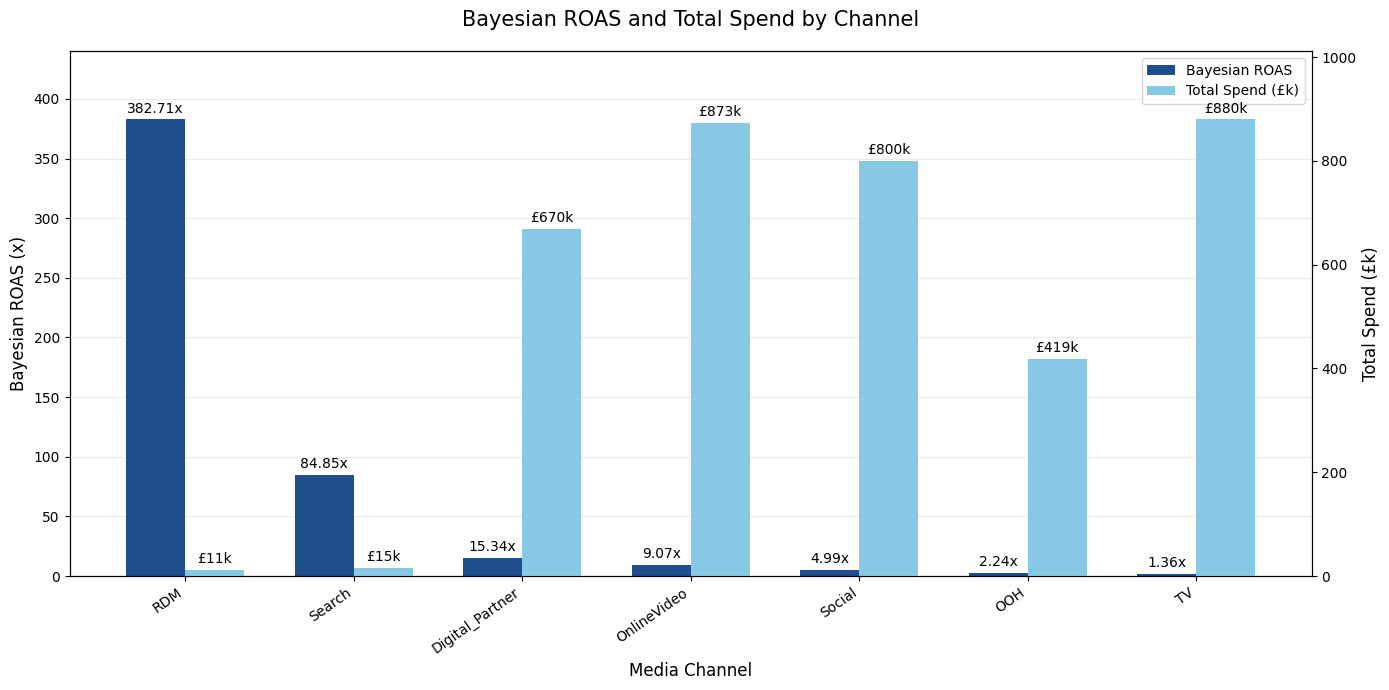

In [64]:


# Get actual Bayesian model results
plot_df = (
    bayesian_roas_df[
        ["Channel", "Total_Spend", "Bayesian_ROAS"]
    ]
    .dropna()
    .sort_values("Bayesian_ROAS", ascending=False)
    .reset_index(drop=True)
)

# Convert total spend to thousands of pounds
plot_df["Spend_k"] = plot_df["Total_Spend"] / 1000

channels = plot_df["Channel"]
roas = plot_df["Bayesian_ROAS"].to_numpy()
spend = plot_df["Spend_k"].to_numpy()

x = np.arange(len(channels))
width = 0.35

# Create figure and dual Y-axes
fig, ax1 = plt.subplots(figsize=(14, 7))
ax2 = ax1.twinx()

# ROAS bars - Dark Blue
bars_roas = ax1.bar(
    x - width / 2,
    roas,
    width=width,
    color="#1F4E8C",
    label="Bayesian ROAS"
)

# Total Spend bars - Light Blue
bars_spend = ax2.bar(
    x + width / 2,
    spend,
    width=width,
    color="#87C8E5",
    label="Total Spend (£k)"
)

# Labels
ax1.set_xlabel("Media Channel", fontsize=12)
ax1.set_ylabel("Bayesian ROAS (x)", fontsize=12)
ax2.set_ylabel("Total Spend (£k)", fontsize=12)

ax1.set_title(
    "Bayesian ROAS and Total Spend by Channel",
    fontsize=15,
    pad=18
)

# X-axis labels
ax1.set_xticks(x)
ax1.set_xticklabels(
    channels,
    rotation=35,
    ha="right"
)

# Axis limits
ax1.set_ylim(0, max(roas) * 1.15)
ax2.set_ylim(0, max(spend) * 1.15)

# ROAS value labels
for bar, value in zip(bars_roas, roas):
    ax1.annotate(
        f"{value:.2f}x",
        xy=(
            bar.get_x() + bar.get_width()/2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

# Media spend value labels
for bar, value in zip(bars_spend, spend):
    ax2.annotate(
        f"£{value:,.0f}k",
        xy=(
            bar.get_x() + bar.get_width()/2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

# Grid
ax1.grid(axis="y", alpha=0.25)
ax1.set_axisbelow(True)

# Combined legend
ax1.legend(
    [bars_roas, bars_spend],
    ["Bayesian ROAS", "Total Spend (£k)"],
    loc="upper right"
)

plt.tight_layout()

# Save graph for GitHub
plt.savefig(
    "Bayesian_ROAS_and_Total_Spend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
